In [28]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib as jb

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

### <font color = 'teal'>Importer et Lire les données<font>


In [31]:
# Importation
df = pd.read_csv("/content/drive/MyDrive/Machine Learning/CLASSIFICATION/DEVOIR/Car_Data (1).csv")
df.head()

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,"Liberte 6,Dakar",9750000,Venant
1,Ford,2009,Manuelle,"Yoff,Dakar",2500000,D'occasion
2,BMW,2015,Automatique,"Cité Damel,Dakar",15500000,D'occasion
3,Ford,2013,Automatique,"Almadies,Dakar",3800000,D'occasion
4,GMC,2014,Automatique,"Hlm,Dakar",7500000,Venant


In [32]:
# Dimension du Dataseet
df.shape

(5507, 6)

In [33]:
# info du dataseet
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Marque           5507 non-null   object
 1   Année            5507 non-null   int64 
 2   Boite_Vitesse    5507 non-null   object
 3   Adresse          5507 non-null   object
 4   Prix             5507 non-null   int64 
 5   Venant_Occasion  5507 non-null   object
dtypes: int64(2), object(4)
memory usage: 258.3+ KB


### <font color = 'teal'>Exploration et preparation des données<font>


In [34]:
# netoyage
df["Adresse"] = df["Adresse"].str.replace(",Dakar","")
df["Adresse"] = df["Adresse"].str.replace(", Dakar","")
df["Adresse"] = df["Adresse"].str.strip()

In [35]:
df.head()

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,Liberte 6,9750000,Venant
1,Ford,2009,Manuelle,Yoff,2500000,D'occasion
2,BMW,2015,Automatique,Cité Damel,15500000,D'occasion
3,Ford,2013,Automatique,Almadies,3800000,D'occasion
4,GMC,2014,Automatique,Hlm,7500000,Venant


In [36]:
df["Adresse"].value_counts()

,count
Adresse,
Almadies,792
Sacré-cœur,448
VDN,341
Liberte 6 extension,334
Liberte 6,290
...,...
Gorée,1
Lac rose,1
Cité asecna,1


In [37]:
# selection les variables catégorielles
cat_data = df.select_dtypes(object)

In [38]:
# décrire les variables catégorielles
cat_data.describe().T

,count,unique,top,freq
Marque,5507,46,Ford,1391
Boite_Vitesse,5507,3,Automatique,4675
Adresse,5507,86,Almadies,792
Venant_Occasion,5507,2,Venant,2855


In [39]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
  val = df[col].value_counts()
  fig = px.bar(x=val.index, y=val.values, color = val.index.astype(str), text_auto=True)
  fig.show()

In [40]:
# Diagrammes en barre des variables catégorielles
for col in cat_data:
  countplot_func(col)

In [41]:
# selection des variables quantitatives
quant_data = df.select_dtypes(include='number')

In [42]:
# décrire les variables quantitatives
quant_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Année,5507.0,2.014508e+03,3.089839e+00,1990.0,2013.0,2015.0,2016.0,2024.0
Prix,5507.0,1.110512e+07,1.619639e+07,1.0,4600000.0,7800000.0,12500000.0,779414131.0


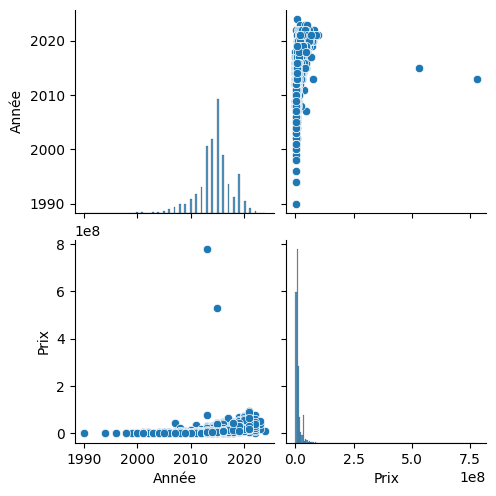

In [43]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show()

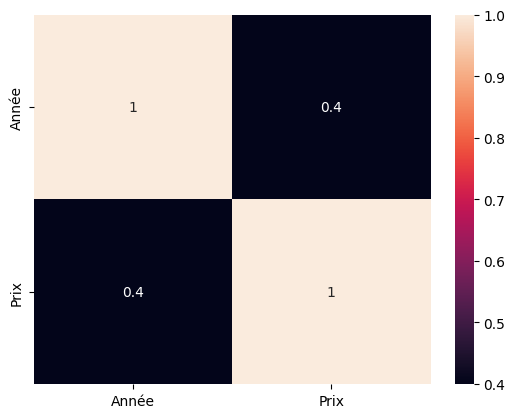

In [44]:
#matrice de correlation
sns.heatmap(quant_data.corr(), annot = True)
plt.show()

In [45]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

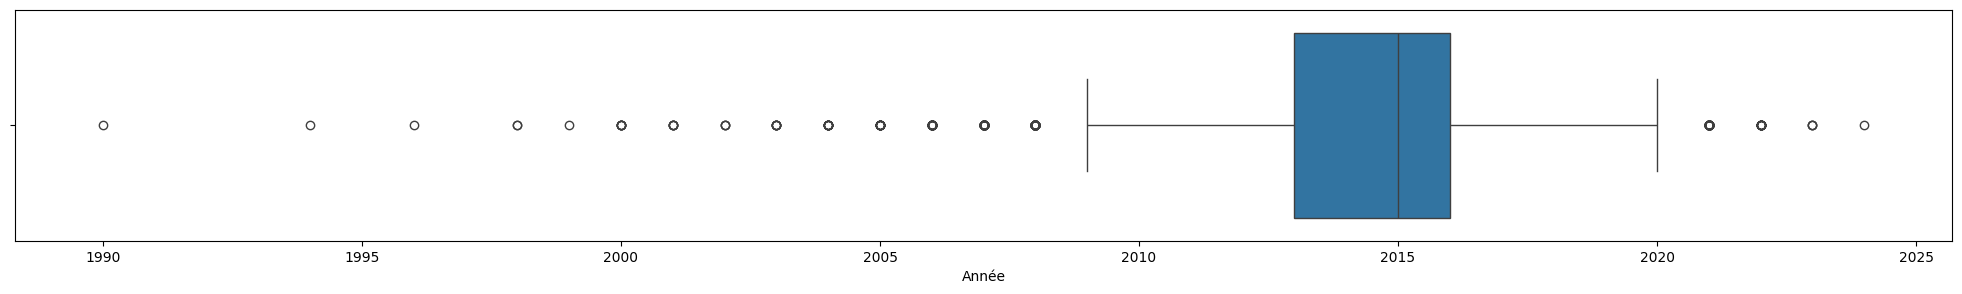

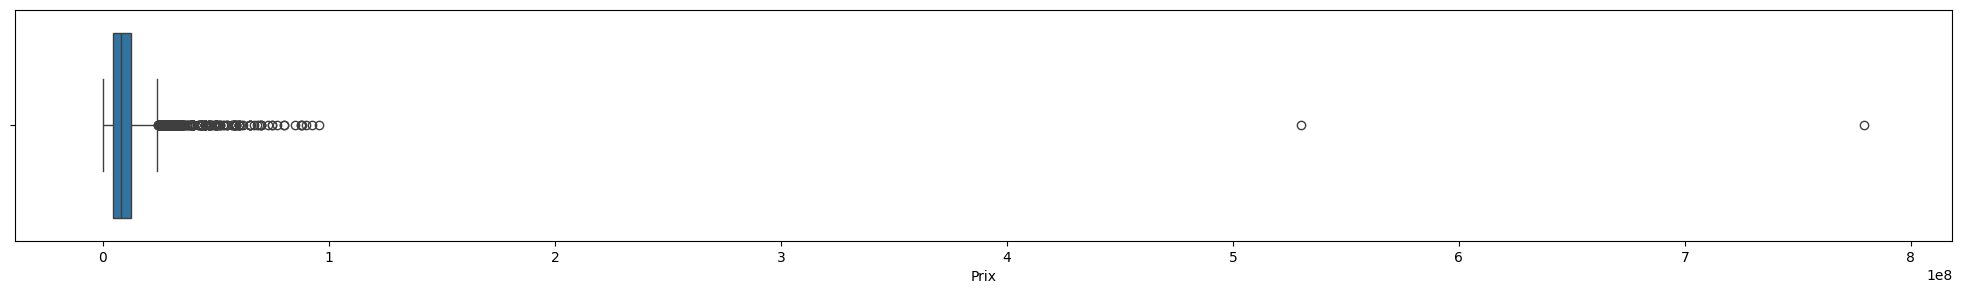

In [46]:
# boxplots des variables quantitatives
for col in quant_data.columns:
  boxplot_func(col)

In [47]:
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
uniques = []
for col in cat_data.columns:
  uniques.append(np.unique(df[col]).tolist())
# sauvegarde
import joblib as jb
jb.dump(uniques,"/content/drive/MyDrive/Machine Learning/CLASSIFICATION/DEVOIR/uniques.joblib")

['/content/drive/MyDrive/Machine Learning/CLASSIFICATION/DEVOIR/uniques.joblib']

###### <font color = 'bisque'> Preparation des données

In [48]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# var = ['yes', 'no', 'no', 'yes'] -----------[1, 0, 0, 1]
encoders = []
for col in cat_data.columns:
    encoder = LabelEncoder()          # un nouvel encodeur par colonne
    df[col] = encoder.fit_transform(df[col])
    encoders.append(encoder)

df.head()

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,30,2017,0,49,9750000,1
1,13,2009,1,83,2500000,0
2,3,2015,0,11,15500000,0
3,13,2013,0,0,3800000,0
4,14,2014,0,38,7500000,1


In [49]:
# sauvegarde les encodeurs
jb.dump(encoders, "/content/drive/MyDrive/Machine Learning/CLASSIFICATION/DEVOIR/encoders.joblib" )

['/content/drive/MyDrive/Machine Learning/CLASSIFICATION/DEVOIR/encoders.joblib']

In [50]:
from sklearn.impute import KNNImputer
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [51]:
# imputation des valeurs extrêmes
for col in quant_data.columns:
  impute_func(df,col)

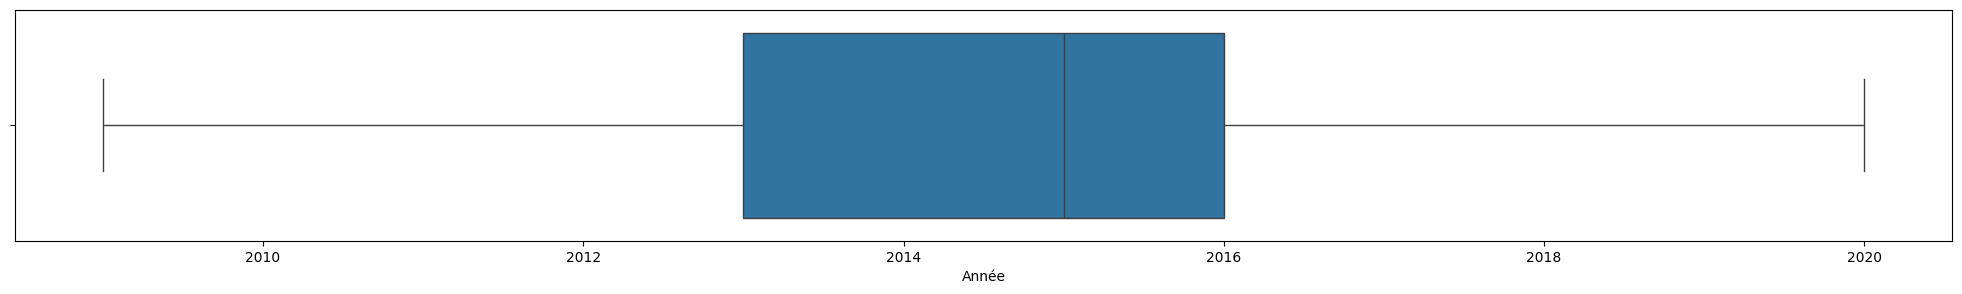

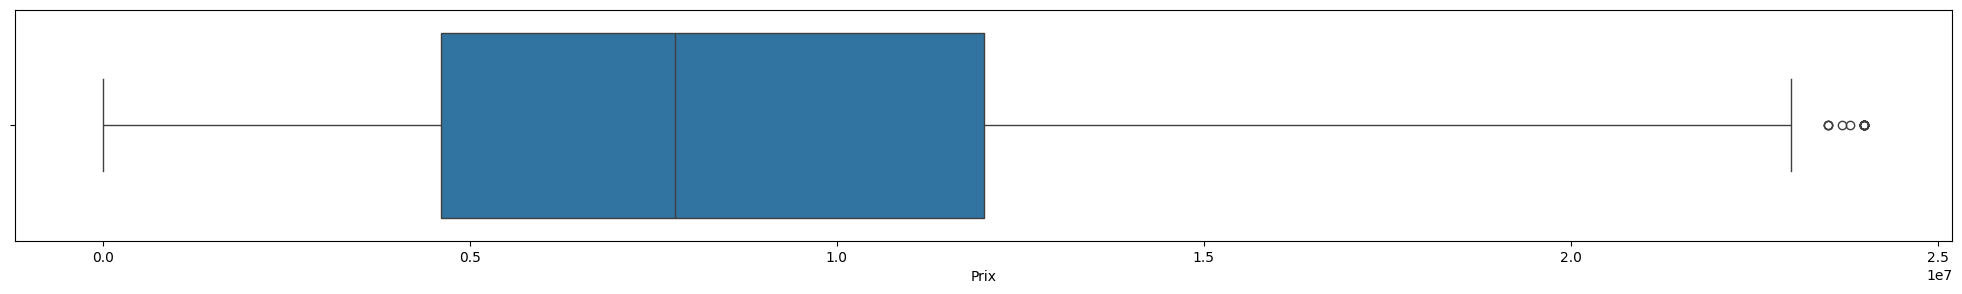

In [52]:
# Réafficher les boxplots
for col in quant_data.columns:
  boxplot_func(col)

In [53]:
# Fractionner les données en variables prédicteurs (x) et variable cibel(y)
x = df.drop('Venant_Occasion',axis = 1).values
y = df.Venant_Occasion.values

In [54]:
# normaliser les données
from sklearn.preprocessing import MinMaxScaler # Z = (X-Xmin)/(Xmax - Xmin)
scaler = MinMaxScaler()
x  = scaler.fit_transform(x)
x[:4]

array([[0.66666667, 0.72727273, 0.        , 0.57647059, 0.40624998],
       [0.28888889, 0.        , 0.5       , 0.97647059, 0.10416663],
       [0.06666667, 0.54545455, 0.        , 0.12941176, 0.64583332],
       [0.28888889, 0.36363636, 0.        , 0.        , 0.1583333 ]])

In [55]:
jb.dump(scaler,"/content/drive/MyDrive/Machine Learning/CLASSIFICATION/DEVOIR/scaler.joblib")

['/content/drive/MyDrive/Machine Learning/CLASSIFICATION/DEVOIR/scaler.joblib']

In [56]:
# splitter les données en train, val et test
# train (80%), val(10%) et test(10%)
#train : données d'entrainement, val: données utiliser pour évaluer chaque et test: données pour tester le modèle le plus performant
from sklearn.model_selection import train_test_split
x_train, x_val_test, y_train, y_val_test = train_test_split(x, y, train_size = 0.8, random_state = 42)# 80% -- 20%
x_val, x_val_test, y_val, y_val_test = train_test_split(x_val_test, y_val_test, train_size = 0.5, random_state = 42)# 80% -- 20%

### <font color = 'teal'>Logistic Regression<font>

In [57]:
from sklearn.model_selection import GridSearchCV, KFold
# Recherche des paramètres optimaux pour la logistic regression
from sklearn.linear_model import LogisticRegression

# Validation croisée et figé
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# dictionnaire params
params={"C":np.logspace(-3,3,10),"penalty": ['l1','l2']}
# instantier le modèle Logistic regression
lg=LogisticRegression()
# instantier le modèle gridsearch
grid=GridSearchCV(lg,params,cv=cv)
# lancer la recherche
grid.fit(x_train,y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LogisticRegression(),
             param_grid={'C': array([1.00000000e-03, 4.64158883e-03, 2.15443469e-02, 1.00000000e-01,
       4.64158883e-01, 2.15443469e+00, 1.00000000e+01, 4.64158883e+01,
       2.15443469e+02, 1.00000000e+03]),
                         'penalty': ['l1', 'l2']})

In [58]:
# Afficher les paramètres optimaux
grid.best_params_

{'C': np.float64(0.021544346900318832), 'penalty': 'l2'}

In [77]:
# Entrainer la logistic regression en utilisant les paramètres optimaux
lg_model = LogisticRegression( C = 0.021544346900318832, penalty = 'l2')
lg_model.fit(x_train,y_train)

LogisticRegression(C=0.021544346900318832)

In [80]:
# fonction d'évaluation
from sklearn.metrics import f1_score, accuracy_score
def evaluation(model):
  y_pred = model.predict(x_val)
  acc = accuracy_score(y_val, y_pred)
  f1 = f1_score(y_val, y_pred, average='micro')
  return acc, f1

In [81]:
# Accuracy et F1 score du modèle sur les données de validation
acc_lg, f1_lg = evaluation(lg_model)
print(f"Accuracy : {acc_lg} --- F1 score : {f1_lg}")

Accuracy : 0.7912885662431942 --- F1 score : 0.7912885662431942


In [62]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# y_pred:  prédictions du modèle sur les données validation
def CM_visualisation(model_objet):

    y_pred = model_objet.predict(x_val)
    # Confusion matrix
    cnf_matr = confusion_matrix(y_val, y_pred, labels=[0,1])

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=["D'occasion","Venant"])
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion') # Définir le titre
    plt.show() # Afficher la figure

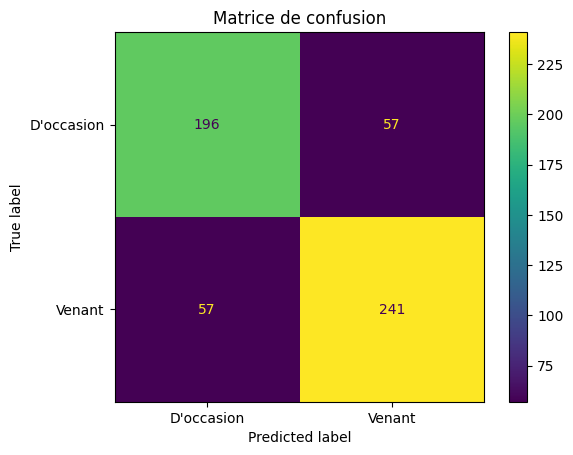

In [63]:
# Matrice de confusion
CM_visualisation(lg_model)

### <font color = 'teal'>Decision Tree<font>

In [64]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
# dictionnaire des params
param__ = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier()
# instantier le modèle gridsearch
grid__ = GridSearchCV(dt, param__, cv = cv)
# entrainer le modèle
grid__.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': array([ 3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])})

In [65]:
# afficher les paramètres optimaux
grid__.best_params_

{'criterion': 'entropy', 'max_depth': np.int64(4)}

In [66]:
# Entrainer le modèle en utilisant les paramètres optimaux
dt_model = DecisionTreeClassifier(criterion='entropy',max_depth=4)
dt_model.fit(x_train,y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=4)

In [82]:
# Accuracy et F1 score du modèle sur les données de validation
# Accuracy et F1 score du modèle sur les données de validation
acc_dt, f1_dt = evaluation(dt_model)
print(f"Accuracy : {acc_dt} --- F1 score : {f1_dt}")

Accuracy : 0.809437386569873 --- F1 score : 0.809437386569873


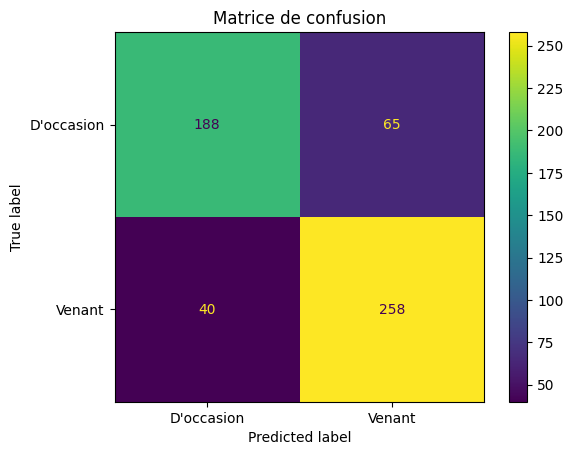

In [68]:
# Matrice de confusion
CM_visualisation(dt_model)

### <font color = 'teal'>Random Forest<font>

In [69]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params = param_grid = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
# instantier le modèle Random Forest
rf = RandomForestClassifier()
# instantier le modèle gridsearch
grid = GridSearchCV(estimator=rf, param_grid=params, cv= cv)
# entrainer le modèle
grid.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [np.int64(3), np.int64(4), np.int64(5),
                                       np.int64(6), np.int64(7), np.int64(8),
                                       np.int64(9), np.int64(10), np.int64(11),
                                       np.int64(12), np.int64(13),
                                       np.int64(14)],
                         'n_estimators': [np.int64(10), np.int64(20),
                                          np.int64(30), np.int64(40),
                                          np.int64(50), np.int64(60),
                                          np.int64(70), np.int64(80),
                                          np.int64(90)]})

In [70]:
# Afficher les paramètres optimaux
grid.best_params_

{'criterion': 'gini', 'max_depth': np.int64(9), 'n_estimators': np.int64(60)}

In [78]:
# Entrainer Random Forest en utilisant les paramètres optimaux
rf_model = RandomForestClassifier(criterion= 'entropy', max_depth= np.int64(9), n_estimators = np.int64(60))
rf_model.fit(x_train,y_train)

RandomForestClassifier(criterion='entropy', max_depth=np.int64(9),
                       n_estimators=np.int64(60))

In [83]:
# Accuracy et F1 score du modèle sur les données de validation
acc_rf, f1_rf = evaluation(rf_model)
print(f"Accuracy : {acc_rf} --- F1 score : {f1_rf}")

Accuracy : 0.8166969147005445 --- F1 score : 0.8166969147005445


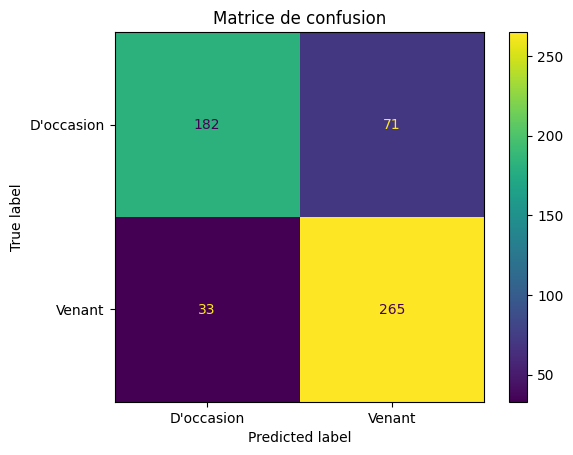

In [73]:
# Matrice de confusion
CM_visualisation(rf_model)

In [84]:
#diagrammes des performances
list_names = ['LG', 'DT', 'RF']
list_acc = [acc_lg, acc_dt, acc_rf]
list_f1 = [f1_lg, f1_dt,f1_rf]
list_final = [list_acc, list_f1]
for i in range(2):
  fig = px.bar(y=list_names, x= list_final[i], color = list_names, text_auto = True)
  fig.show()

### <font color ='bisque'>Tester le modèle le plus performant<font>


In [85]:
# echantillons
x_test_10 = x_val_test[:10]
y_test_10 = y_val_test[:10]
# prédictions
y_pred_10 = rf_model.predict(x_test_10)
classnames = ["D'occasion", "Venant"]
for i in range(10):
  print(f"Prédiction {str(i +1)} : {classnames[y_pred_10[i]]}  -- {classnames[y_test_10[i]]}")

Prédiction 1 : D'occasion  -- D'occasion
Prédiction 2 : Venant  -- Venant
Prédiction 3 : D'occasion  -- D'occasion
Prédiction 4 : Venant  -- Venant
Prédiction 5 : D'occasion  -- Venant
Prédiction 6 : D'occasion  -- D'occasion
Prédiction 7 : Venant  -- Venant
Prédiction 8 : Venant  -- D'occasion
Prédiction 9 : D'occasion  -- Venant
Prédiction 10 : D'occasion  -- D'occasion


In [86]:
# télécharger le modèle le plus performant
jb.dump(rf_model,"/content/drive/MyDrive/Machine Learning/CLASSIFICATION/DEVOIR/rf_model.joblib")

['/content/drive/MyDrive/Machine Learning/CLASSIFICATION/DEVOIR/rf_model.joblib']